# QQQ 长期择时：盈亏同源，不等于风险最大才赚最多

实际回放 2000-03-08—2025-12-31；此前 252 日预热。主成本单边 10 bps，收盘信号下一交易日开盘执行，现金利率代理计息。先读[结果报告](../reports/08-qqq-long-term-results.md)和[预登记方案](../reports/07-qqq-risk-and-timing-playbook.md)。

当前版本供应商复权近似，非历史 PIT；未核验全部发行人分红支付日。所有结果来自真实日线，不使用合成行情。运行前在仓库根目录执行 `python -m tools.research_playbook.qqq_timing`，下列单元格只读取输出并验证摘要。

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
if not (root / 'tools/research_playbook').exists():
    root = root.parents[1]
out = root / 'var/research-playbook/qqq-long'
evidence = json.loads((out / 'evidence.json').read_text())
for rel, expected in evidence['code_sha256'].items():
    assert hashlib.sha256((root / rel).read_bytes()).hexdigest() == expected, rel
for source, key in [('qqq_long_2025','source'),('irx_long_2025','cash_source')]:
    raw = root / f'var/research-playbook/data/raw/{source}.source'
    assert hashlib.sha256(raw.read_bytes()).hexdigest() == evidence[key]['sha256']
summary = pd.read_csv(out/'summary.csv').set_index('rule')
returns = pd.read_csv(out/'returns.csv', index_col='day', parse_dates=True)
labels = {'hold':'Buy & hold','cash':'Cash proxy','fixed25':'25% QQQ','fixed50':'50% QQQ','fixed75':'75% QQQ','macd_12_26_9':'MACD 12/26/9','sma200':'SMA 200','sma250':'SMA 250'}
core = ['hold','fixed50','macd_12_26_9','sma200','sma250']
plt.rcParams.update({'figure.figsize':(11,5),'axes.grid':True,'grid.alpha':.2})
print('输入:',evidence['first'],evidence['last'],evidence['rows'],'日；日历缺口',evidence['calendar_missing'])
display(summary[['cagr','maxDrawdown','volatility','finalNav','tradeCount']].round(4))

输入: 1999-03-10 2025-12-31 6746 日；日历缺口 0


,cagr,maxDrawdown,volatility,finalNav,tradeCount
rule,,,,,
hold,0.0755,-0.8296,0.2654,653931.4411,2
cash,0.0189,-0.0000,0.0016,162277.8016,0
fixed25,0.0380,-0.2767,0.0648,261679.0616,311
fixed50,0.0539,-0.5380,0.1304,387620.4748,311
fixed75,0.0665,-0.7145,0.1972,526465.5083,311
macd_12_26_9,-0.0062,-0.7603,0.1657,85140.2370,522
sma200,0.0694,-0.5154,0.1637,565007.5745,186
macd_8_17_9,-0.0098,-0.7907,0.1695,77621.2448,664
macd_19_39_9,0.0070,-0.6438,0.1607,119582.2192,414


## 1. 长期财富与途中损失

净值用对数坐标，能同时看清早期深跌和后期增长。回撤从历史最高净值计算，包含初始本金。2000 年起点靠近泡沫顶部，不能只凭这条全期曲线选策略。250 日均线为预先列入的敏感性版本，不是独立验证的最佳参数。

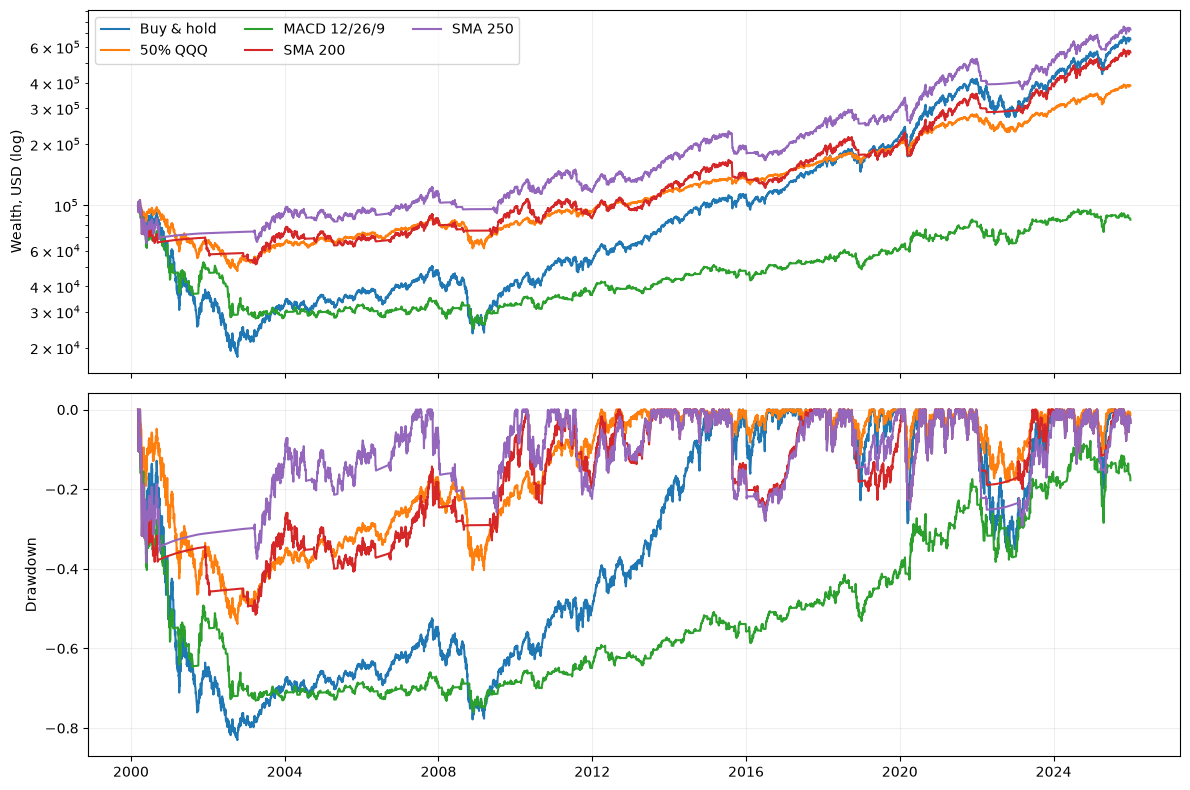

In [2]:
fig, axes = plt.subplots(2,1,figsize=(12,8),sharex=True)
for rule in core:
    wealth=100000*(1+returns[rule]).cumprod()
    peak=np.maximum.accumulate(np.r_[100000,wealth])[1:]
    axes[0].plot(wealth,label=labels[rule])
    axes[1].plot(wealth/peak-1,label=labels[rule])
axes[0].set_yscale('log'); axes[0].set_ylabel('Wealth, USD (log)'); axes[0].legend(ncol=3)
axes[1].set_ylabel('Drawdown'); fig.tight_layout(); plt.show()

## 2. 风险与收益不是单一排名

固定仓位大体呈现风险与收益一起增加；MACD 比相近暴露的固定组合弱。250 日均线在这段样本中提供反例：较低风险与较高收益可以同时出现。风险定义也影响判断，波动、最大回撤和收益不能混为一个指标。

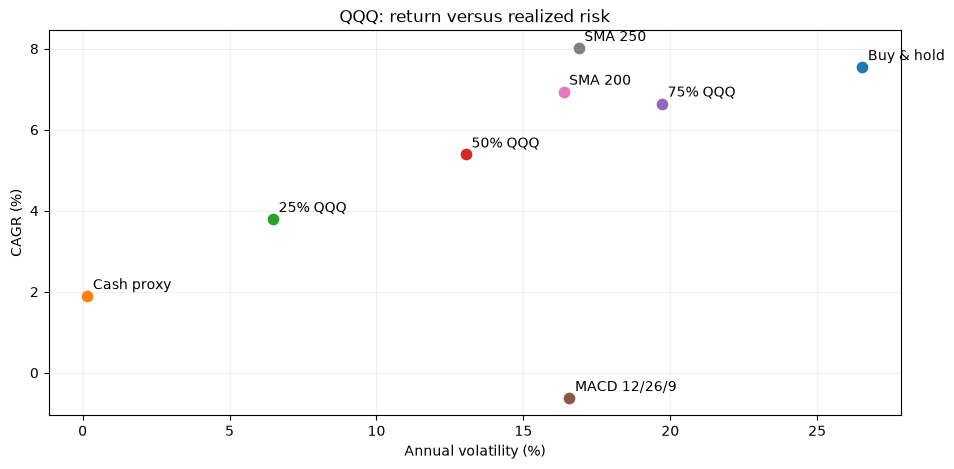

,rule,mode,cagr,volatility,maxDrawdown
0,macd_12_26_9,exposure,0.0913,0.1137,-0.3021
1,macd_12_26_9,exposure_actual,0.0496,0.1340,-0.2940
2,macd_12_26_9,volatility,0.1014,0.1338,-0.3859
3,macd_12_26_9,volatility_actual,0.0496,0.1340,-0.2940
4,sma200,exposure,0.1199,0.1749,-0.4389
5,sma200,exposure_actual,0.1120,0.1556,-0.2702
6,sma200,volatility,0.1085,0.1672,-0.4675
7,sma200,volatility_actual,0.1120,0.1556,-0.2702


In [3]:
fig,ax=plt.subplots()
for rule,label in labels.items():
    ax.scatter(summary.loc[rule,'volatility']*100,summary.loc[rule,'cagr']*100,s=55)
    ax.annotate(label,(summary.loc[rule,'volatility']*100,summary.loc[rule,'cagr']*100),xytext=(4,5),textcoords='offset points')
ax.set(xlabel='Annual volatility (%)',ylabel='CAGR (%)',title='QQQ: return versus realized risk');plt.show()
display(pd.read_csv(out/'matched.csv')[['rule','mode','cagr','volatility','maxDrawdown']].round(4))

## 3. 换一个起点还能成立吗

每月取一个起点，观察连续策略路径未来 10/20 年的年化差额。零线以上才跑赢持有。窗口高度重叠，不能把 70 个二十年窗口当作 70 次独立试验。

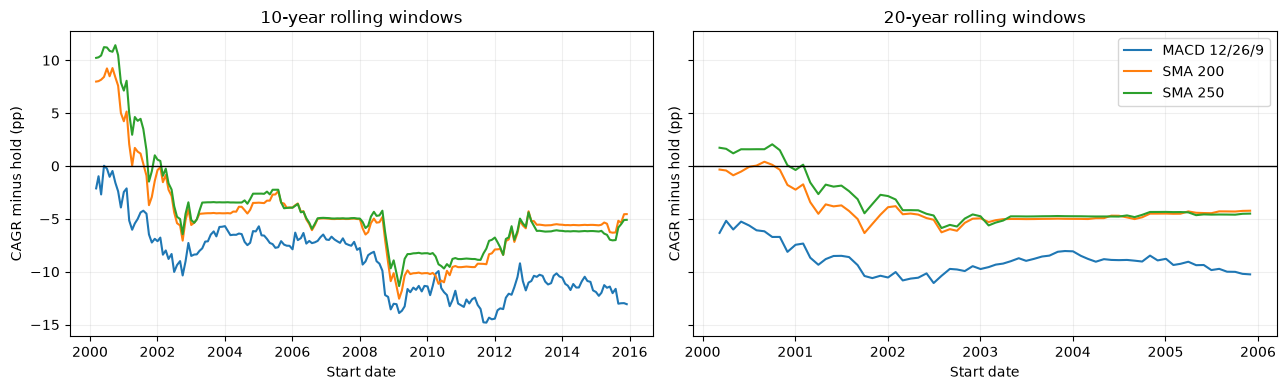

In [4]:
rolling=pd.read_csv(out/'rolling.csv',parse_dates=['start'])
fig,axes=plt.subplots(1,2,figsize=(13,4),sharey=True)
for ax,years in zip(axes,[10,20]):
    for rule in ['macd_12_26_9','sma200','sma250']:
        s=rolling[(rolling.years==years)&(rolling.rule==rule)]
        ax.plot(s.start,s.delta*100,label=labels[rule])
    ax.axhline(0,color='black',lw=1);ax.set(title=f'{years}-year rolling windows',xlabel='Start date',ylabel='CAGR minus hold (pp)')
axes[1].legend();fig.tight_layout();plt.show()

## 4. 躲过下跌的收益与错过上涨的代价

以下按基准当日涨跌划分全部日期，对数净回报差可以精确加总。它包含时点、利息和成本，不是纯空仓机会成本的因果估计。柱高不是收益百分比；合计取指数才是最终财富比。

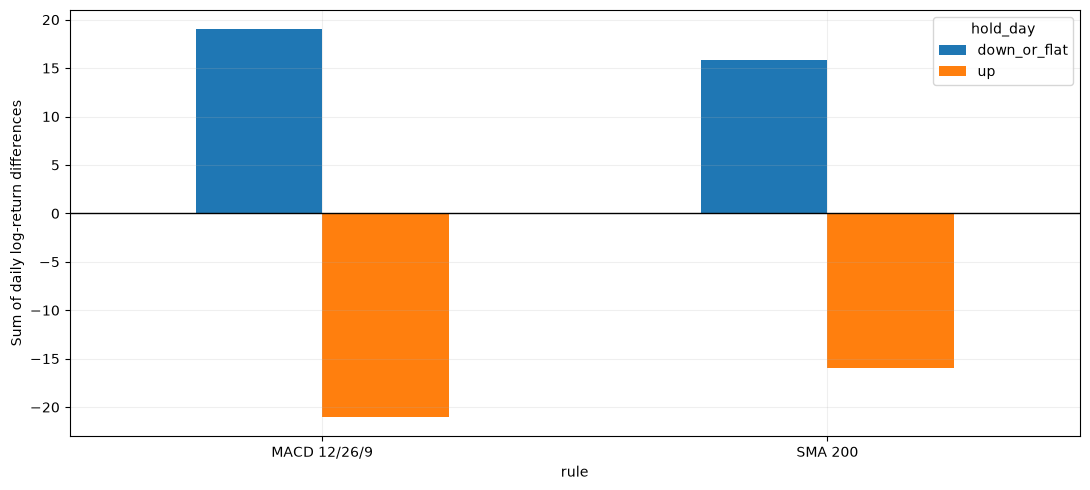

终值比例: {'macd_12_26_9': 0.13019749720087873, 'sma200': 0.8640165298479409}


In [5]:
a=pd.read_csv(out/'attribution.csv')
pivot=a.pivot(index='rule',columns='hold_day',values='log_wealth_difference')
pivot.rename(index=labels).plot.bar(rot=0)
plt.ylabel('Sum of daily log-return differences');plt.axhline(0,color='black',lw=1);plt.tight_layout();plt.show()
print('终值比例:',np.exp(pivot.sum(axis=1)).to_dict())

## 5. MACD 差，不代表“卖出前已经跌了”

信号前 20 日数据与买卖方向对照：MACD 多数卖出仍发生在过去 20 日上涨时，更像是涨势放缓触发退出。全部可评分日过去 20 日上涨比例约 62.55%；不能只看买入前上涨比例就下追涨结论。下面只完成主 20 日尺度，5/60 日及逐笔震荡分类尚未做。

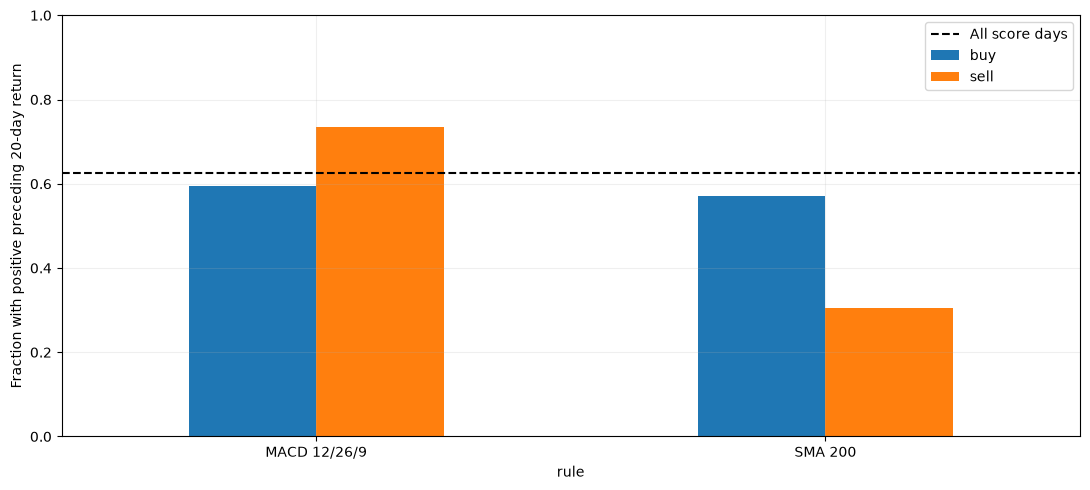

,rule,side,count,past20_mean,positive_fraction
0,macd_12_26_9,sell,260,0.0129,0.7346
1,macd_12_26_9,buy,261,0.0043,0.5939
2,sma200,sell,92,-0.0247,0.3043
3,sma200,buy,93,0.0094,0.5699


In [6]:
events=pd.read_csv(out/'events.csv')
events.pivot(index='rule',columns='side',values='positive_fraction').rename(index=labels).plot.bar(rot=0)
plt.axhline(evidence['baseline_past20_positive'],color='black',ls='--',label='All score days')
plt.ylabel('Fraction with positive preceding 20-day return');plt.ylim(0,1);plt.legend();plt.tight_layout();plt.show()
display(events.round(4))

## 6. 成本、参数和不确定性

标准 MACD 零成本仍落后；基础成本使复利变负。200 日均线与持有的差额较小，容易受成本影响。块抽样是已实现配对收益差的不确定性，均线区间跨零；不代表未来收益保证，也不是 CAGR 差区间。

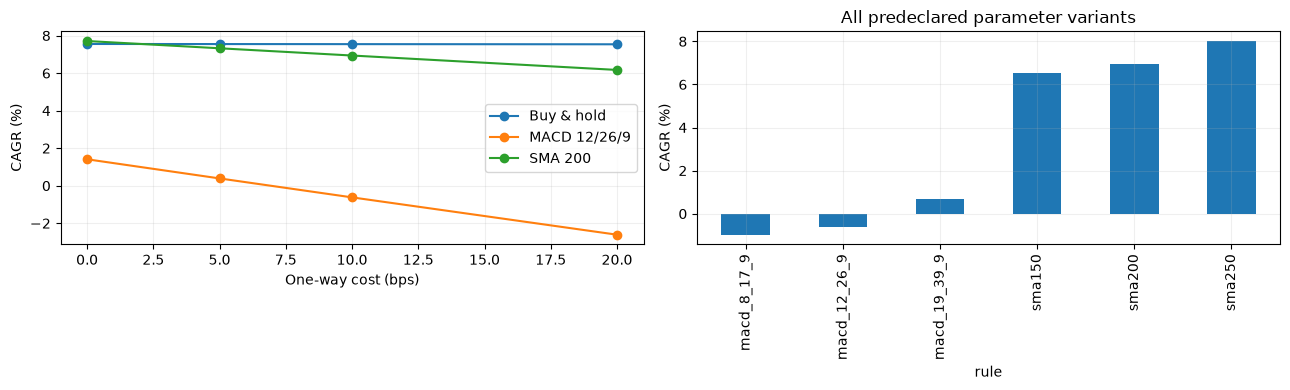

MACD 12/26/9 annualized arithmetic excess-return difference


,block,mean,low,high
0,21,-0.1005,-0.1665,-0.0289
1,63,-0.1005,-0.1584,-0.0338
2,126,-0.1005,-0.1497,-0.0310


SMA 200 annualized arithmetic excess-return difference


,block,mean,low,high
0,21,-0.0274,-0.0997,0.0450
1,63,-0.0274,-0.0984,0.0507
2,126,-0.0274,-0.0896,0.0522


In [7]:
costs=pd.read_csv(out/'costs.csv')
fig,axes=plt.subplots(1,2,figsize=(13,4))
for rule in ['hold','macd_12_26_9','sma200']:
    s=costs[costs.rule==rule];axes[0].plot(s.cost_bps,s.cagr*100,marker='o',label=labels[rule])
axes[0].set(xlabel='One-way cost (bps)',ylabel='CAGR (%)');axes[0].legend()
s=summary.loc[['macd_8_17_9','macd_12_26_9','macd_19_39_9','sma150','sma200','sma250'],'cagr']*100
s.plot.bar(ax=axes[1]);axes[1].set(ylabel='CAGR (%)',title='All predeclared parameter variants');fig.tight_layout();plt.show()
for rule,result in evidence['bootstrap'].items():
    print(labels[rule], 'annualized arithmetic excess-return difference')
    display(pd.DataFrame(result).round(4))

## 怎样读结论

- 本窗口支持：标准 MACD 的频繁择时损失超过降低暴露的好处，且不只是交易成本造成。
- 不能推出：MACD 必然是追涨杀跌、所有趋势策略都差、承担最多风险才能得到更多收益。
- 200 日均线降低回撤但牺牲部分收益；250 日版本是本历史中的反例，不是未来优势证明。

仍缺完整公司行动/PIT核验、真实税费/逐日滑点、全部计划指标、沪深300复制及未来观察。这里的统计不确定性不包含这些数据和执行误差。原件来自 Yahoo chart QQQ 和 ^IRX；来源 URL、取得时点、SHA-256、代码摘要见 `evidence.json`。